Example Circuit

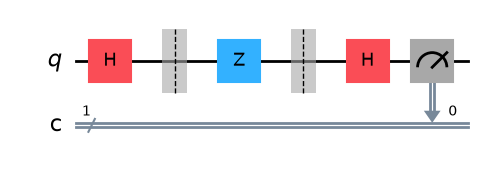

In [14]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display
import matplotlib.pyplot as plt

example = QuantumCircuit(1, 1)

example.h(0)       # Prepare |+>
example.barrier()

example.z(0)       # Insert a phase-flip error
example.barrier()

example.h(0)       # Measure in the X basis
example.measure(0, 0)

display(example.draw("mpl"))
plt.close()

For Bit-Flip Error

Without error


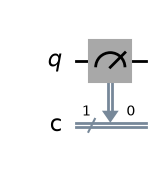

With error


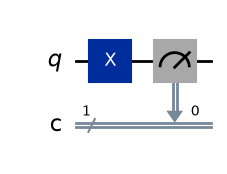

Without error: {'0': 1000}
With error: {'1': 1000}


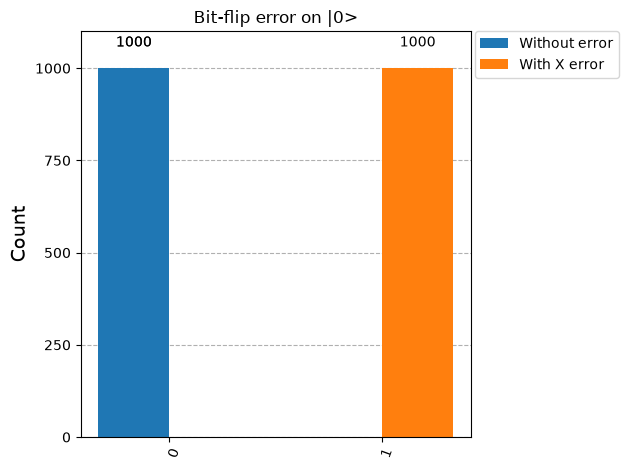

In [15]:
# Create the simulator.
simulator = AerSimulator()

# Circuit without error: start in |0> and measure.
ideal = QuantumCircuit(1, 1)
ideal.measure(0, 0)

# Circuit with error: X changes |0> into |1>.
faulty = QuantumCircuit(1, 1)
faulty.x(0)
faulty.measure(0, 0)

# Display both circuits.
print("Without error")
display(ideal.draw("mpl"))
plt.close()

print("With error")
display(faulty.draw("mpl"))
plt.close()

# Prepare both circuits for simulation.
circuit_1 = transpile(ideal, simulator)
circuit_2 = transpile(faulty, simulator)

# Run each circuit 1000 times.
result_1 = simulator.run(circuit_1, shots=1000).result()
result_2 = simulator.run(circuit_2, shots=1000).result()

# Get the measurement counts.
counts_1 = result_1.get_counts()
counts_2 = result_2.get_counts()

print("Without error:", counts_1)
print("With error:", counts_2)

# Display the comparison histogram.
display(plot_histogram(
    [counts_1, counts_2],
    legend=["Without error", "With X error"],
    title="Bit-flip error on |0>"
))
plt.close()

For Phase-Flip Error

Without error


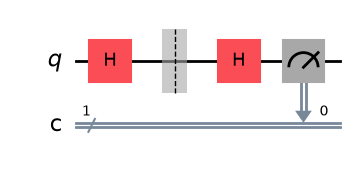

With Z error


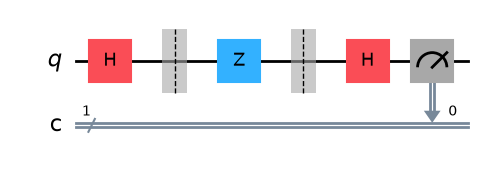

Without error: {'0': 1000}
With Z error: {'1': 1000}


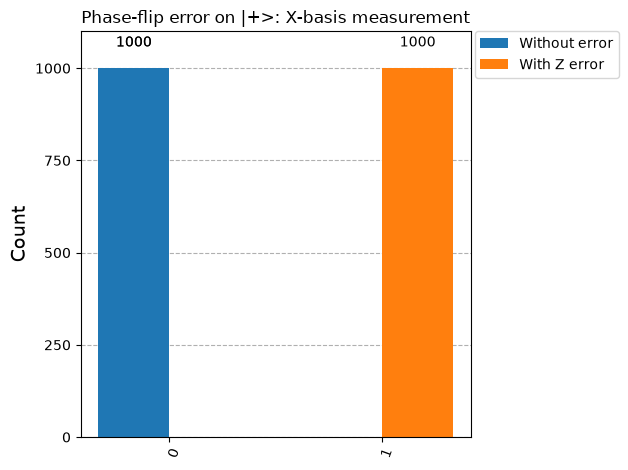

In [16]:
error_simulator = simulator
title = "Phase-flip error on |+>"

# Without error.
ideal = QuantumCircuit(1, 1)

ideal.h(0)          # Prepare |+>
ideal.barrier()

ideal.h(0)          # X-basis measurement
ideal.measure(0, 0)

# With a Z error.
faulty = QuantumCircuit(1, 1)

faulty.h(0)         # Prepare |+>
faulty.barrier()

faulty.z(0)         # Introduce the error
faulty.barrier()

faulty.h(0)         # X-basis measurement
faulty.measure(0, 0)
print("Without error")
display(ideal.draw("mpl"))
plt.close()

print("With Z error")
display(faulty.draw("mpl"))
plt.close()
# Prepare the circuits.
circuit_1 = transpile(ideal, simulator)
circuit_2 = transpile(faulty, simulator)

# Run each circuit 1000 times.
result_1 = simulator.run(circuit_1, shots=1000).result()
result_2 = simulator.run(circuit_2, shots=1000).result()

# Get the counts.
counts_1 = result_1.get_counts()
counts_2 = result_2.get_counts()

print("Without error:", counts_1)
print("With Z error:", counts_2)

# Show the histogram.
display(plot_histogram(
    [counts_1, counts_2],
    legend=["Without error", "With Z error"],
    title="Phase-flip error on |+>: X-basis measurement"
))
plt.close()

For Y Error

Without error


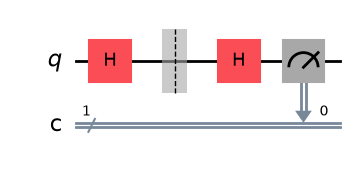

With Y error


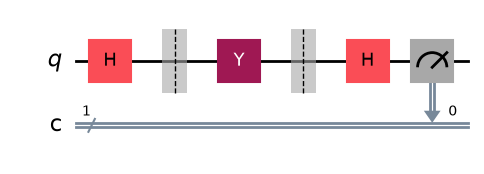

Without error: {'0': 1000}
With Y error: {'1': 1000}


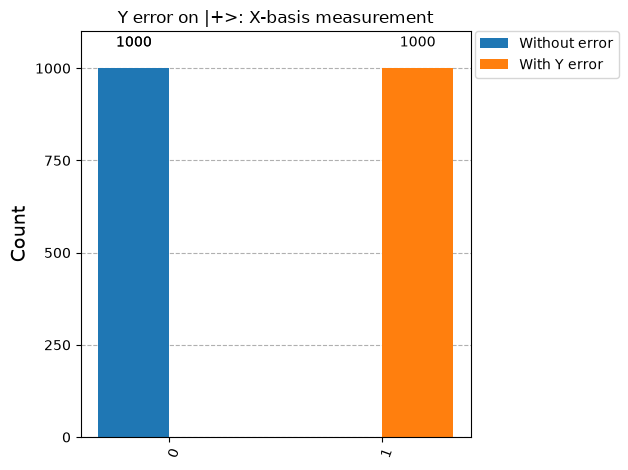

In [17]:
error_simulator = simulator
title = "Y error on |+>"

# Without error.
ideal = QuantumCircuit(1, 1)

ideal.h(0)
ideal.barrier()

ideal.h(0)
ideal.measure(0, 0)

# With a Y error.
faulty = QuantumCircuit(1, 1)

faulty.h(0)
faulty.barrier()

faulty.y(0)
faulty.barrier()

faulty.h(0)
faulty.measure(0, 0)
# Display both circuits.
print("Without error")
display(ideal.draw("mpl"))
plt.close()

print("With Y error")
display(faulty.draw("mpl"))
plt.close()

# Prepare the circuits.
circuit_1 = transpile(ideal, simulator)
circuit_2 = transpile(faulty, simulator)

# Run each circuit 1000 times.
result_1 = simulator.run(circuit_1, shots=1000).result()
result_2 = simulator.run(circuit_2, shots=1000).result()

# Get the counts.
counts_1 = result_1.get_counts()
counts_2 = result_2.get_counts()

print("Without error:", counts_1)
print("With Y error:", counts_2)

# Display the histogram.
display(plot_histogram(
    [counts_1, counts_2],
    legend=["Without error", "With Y error"],
    title="Y error on |+>: X-basis measurement"
))
plt.close()

Energy Relaxation

Without error


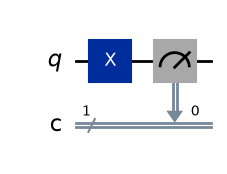

With energy relaxation


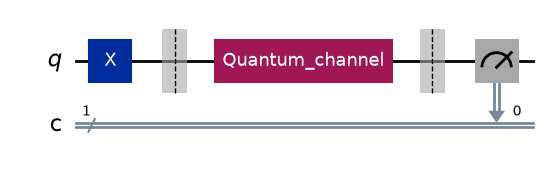

Without error: {'1': 1000}
With energy relaxation: {'0': 300, '1': 700}


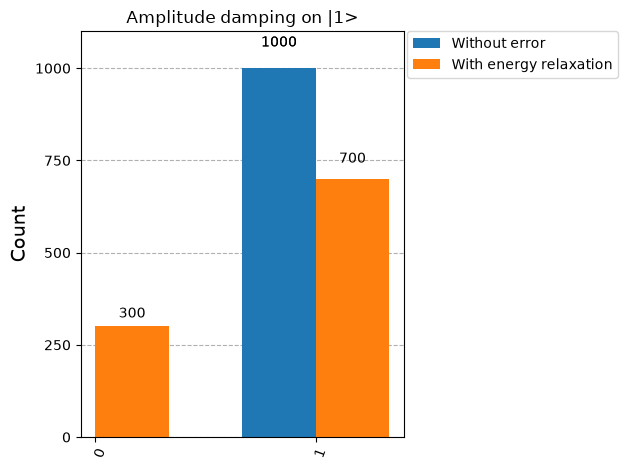

In [18]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import amplitude_damping_error
from qiskit.visualization import plot_histogram
from IPython.display import display
import matplotlib.pyplot as plt

simulator = AerSimulator()

# Probability of relaxation from |1> to |0>.
error = amplitude_damping_error(0.30)

# Circuit without error.
ideal = QuantumCircuit(1, 1)

ideal.x(0)          # Prepare |1>
ideal.measure(0, 0)

# Circuit with energy relaxation.
faulty = QuantumCircuit(1, 1)

faulty.x(0)         # Prepare |1>
faulty.barrier()

faulty.append(error.to_instruction(), [0])

faulty.barrier()
faulty.measure(0, 0)

# Display the circuits.
print("Without error")
display(ideal.draw("mpl"))
plt.close()

print("With energy relaxation")
display(faulty.draw("mpl"))
plt.close()

# Prepare the circuits.
circuit_1 = transpile(ideal, simulator, optimization_level=0)
circuit_2 = transpile(faulty, simulator, optimization_level=0)

# Run each circuit 1000 times.
result_1 = simulator.run(circuit_1, shots=1000).result()
result_2 = simulator.run(circuit_2, shots=1000).result()

# Get the counts.
counts_1 = result_1.get_counts()
counts_2 = result_2.get_counts()

print("Without error:", counts_1)
print("With energy relaxation:", counts_2)

# Display the histogram.
display(plot_histogram(
    [counts_1, counts_2],
    legend=["Without error", "With energy relaxation"],
    title="Amplitude damping on |1>"
))
plt.close()

For Dephasing

Without error


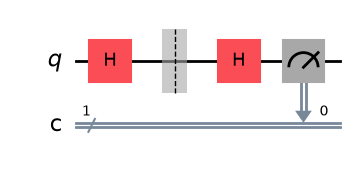

With dephasing


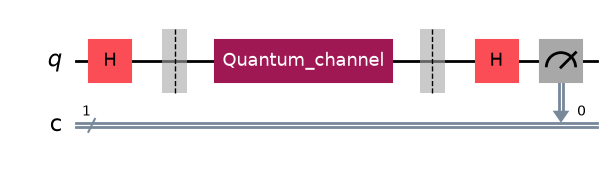

Without error: {'0': 1000}
With dephasing: {'1': 145, '0': 855}


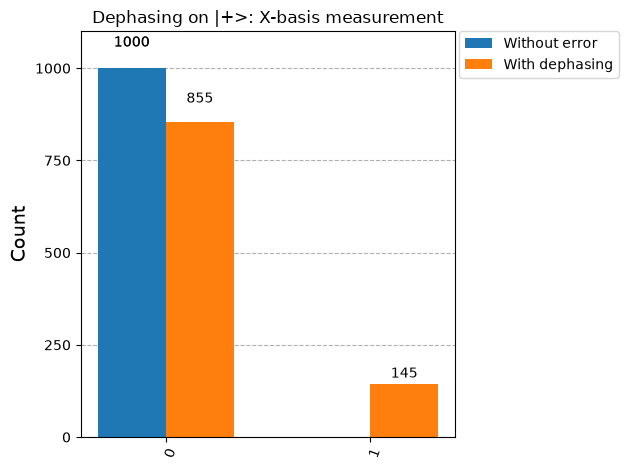

In [19]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import phase_damping_error
from qiskit.visualization import plot_histogram
from IPython.display import display
import matplotlib.pyplot as plt

simulator = AerSimulator()

# Coherence factor = 0.70.
# Phase-damping parameter = 1 - (0.70)**2 = 0.51.
error = phase_damping_error(0.51)

# Circuit without error.
ideal = QuantumCircuit(1, 1)

ideal.h(0)          # Prepare |+>
ideal.barrier()

ideal.h(0)          # X-basis measurement
ideal.measure(0, 0)

# Circuit with dephasing.
faulty = QuantumCircuit(1, 1)

faulty.h(0)         # Prepare |+>
faulty.barrier()

faulty.append(error.to_instruction(), [0])
faulty.barrier()

faulty.h(0)         # X-basis measurement
faulty.measure(0, 0)

# Display the circuits.
print("Without error")
display(ideal.draw("mpl"))
plt.close()

print("With dephasing")
display(faulty.draw("mpl"))
plt.close()

# Prepare the circuits.
circuit_1 = transpile(ideal, simulator, optimization_level=0)
circuit_2 = transpile(faulty, simulator, optimization_level=0)

# Run each circuit 1000 times.
result_1 = simulator.run(circuit_1, shots=1000).result()
result_2 = simulator.run(circuit_2, shots=1000).result()

# Get the counts.
counts_1 = result_1.get_counts()
counts_2 = result_2.get_counts()

print("Without error:", counts_1)
print("With dephasing:", counts_2)

# Display the histogram.
display(plot_histogram(
    [counts_1, counts_2],
    legend=["Without error", "With dephasing"],
    title="Dephasing on |+>: X-basis measurement"
))
plt.close()

For Depolarizing Noise

Without error


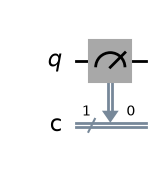

With depolarizing noise


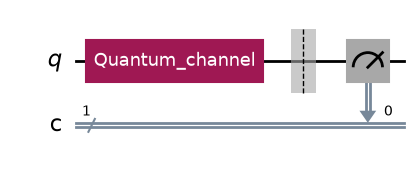

Without error: {'0': 1000}
With depolarizing noise: {'1': 182, '0': 818}


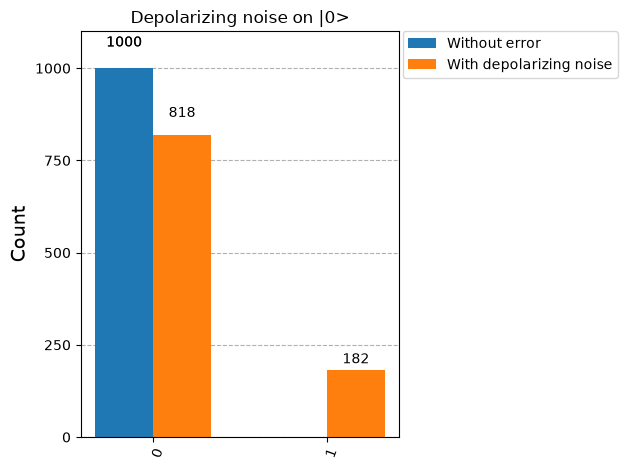

In [20]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import depolarizing_error
from qiskit.visualization import plot_histogram
from IPython.display import display
import matplotlib.pyplot as plt

simulator = AerSimulator()

# Depolarizing parameter = 0.30 for one qubit.
error = depolarizing_error(0.30, 1)

# Circuit without error: initial state |0>.
ideal = QuantumCircuit(1, 1)

ideal.measure(0, 0)

# Circuit with depolarizing noise.
faulty = QuantumCircuit(1, 1)

faulty.append(error.to_instruction(), [0])
faulty.barrier()

faulty.measure(0, 0)

# Display the circuits.
print("Without error")
display(ideal.draw("mpl"))
plt.close()

print("With depolarizing noise")
display(faulty.draw("mpl"))
plt.close()

# Prepare the circuits.
circuit_1 = transpile(ideal, simulator, optimization_level=0)
circuit_2 = transpile(faulty, simulator, optimization_level=0)

# Run each circuit 1000 times.
result_1 = simulator.run(circuit_1, shots=1000).result()
result_2 = simulator.run(circuit_2, shots=1000).result()

# Get the counts.
counts_1 = result_1.get_counts()
counts_2 = result_2.get_counts()

print("Without error:", counts_1)
print("With depolarizing noise:", counts_2)

# Display the histogram.
display(plot_histogram(
    [counts_1, counts_2],
    legend=["Without error", "With depolarizing noise"],
    title="Depolarizing noise on |0>"
))
plt.close()

For Unwanted Rx Rotation

Without error


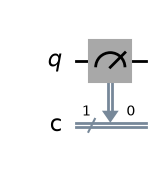

With unwanted Rx rotation


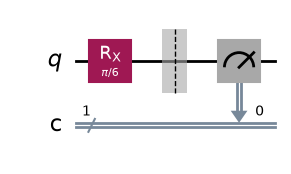

Without error: {'0': 1000}
With unwanted Rx rotation: {'1': 80, '0': 920}


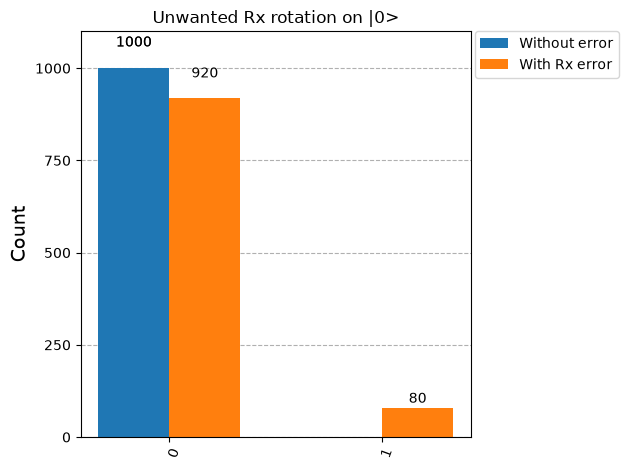

In [21]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np

simulator = AerSimulator()

# Unwanted rotation angle: pi/6 radians = 30 degrees.
delta = np.pi / 6

# Circuit without error: the qubit stays in |0>.
ideal = QuantumCircuit(1, 1)

ideal.measure(0, 0)

# Circuit with an unwanted Rx rotation.
faulty = QuantumCircuit(1, 1)

faulty.rx(delta, 0)
faulty.barrier()

faulty.measure(0, 0)

# Display the circuits.
print("Without error")
display(ideal.draw("mpl"))
plt.close()

print("With unwanted Rx rotation")
display(faulty.draw("mpl"))
plt.close()

# Prepare the circuits.
circuit_1 = transpile(ideal, simulator, optimization_level=0)
circuit_2 = transpile(faulty, simulator, optimization_level=0)

# Run each circuit 1000 times.
result_1 = simulator.run(circuit_1, shots=1000).result()
result_2 = simulator.run(circuit_2, shots=1000).result()

# Get the counts.
counts_1 = result_1.get_counts()
counts_2 = result_2.get_counts()

print("Without error:", counts_1)
print("With unwanted Rx rotation:", counts_2)

# Display the histogram.
display(plot_histogram(
    [counts_1, counts_2],
    legend=["Without error", "With Rx error"],
    title="Unwanted Rx rotation on |0>"
))
plt.close()

For Unwanted Rz Rotation

Without error


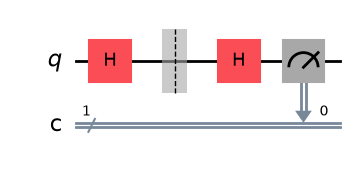

With unwanted Rz rotation


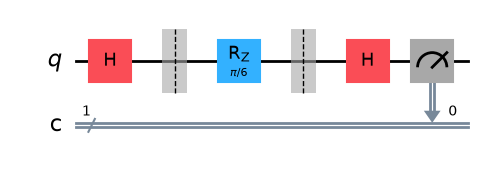

Without error: {'0': 1000}
With unwanted Rz rotation: {'1': 61, '0': 939}


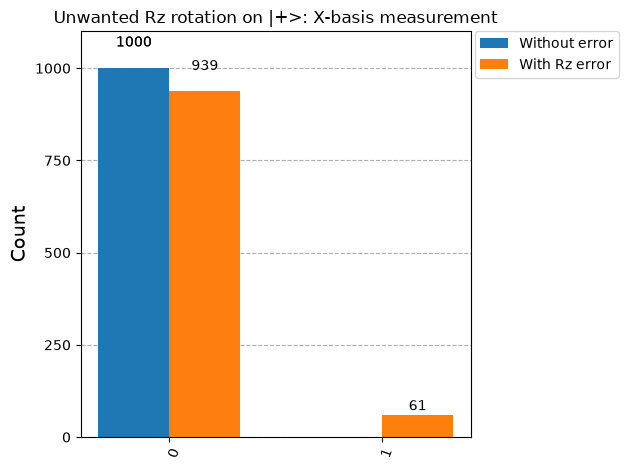

In [22]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np

simulator = AerSimulator()

# Unwanted rotation angle: pi/6 radians = 30 degrees.
delta = np.pi / 6

# Circuit without error.
ideal = QuantumCircuit(1, 1)

ideal.h(0)          # Prepare |+>
ideal.barrier()

ideal.h(0)          # X-basis measurement
ideal.measure(0, 0)

# Circuit with an unwanted Rz rotation.
faulty = QuantumCircuit(1, 1)

faulty.h(0)         # Prepare |+>
faulty.barrier()

faulty.rz(delta, 0) # Unwanted phase rotation
faulty.barrier()

faulty.h(0)         # X-basis measurement
faulty.measure(0, 0)

# Display the circuits.
print("Without error")
display(ideal.draw("mpl"))
plt.close()

print("With unwanted Rz rotation")
display(faulty.draw("mpl"))
plt.close()

# Prepare the circuits.
circuit_1 = transpile(ideal, simulator, optimization_level=0)
circuit_2 = transpile(faulty, simulator, optimization_level=0)

# Run each circuit 1000 times.
result_1 = simulator.run(circuit_1, shots=1000).result()
result_2 = simulator.run(circuit_2, shots=1000).result()

# Get the counts.
counts_1 = result_1.get_counts()
counts_2 = result_2.get_counts()

print("Without error:", counts_1)
print("With unwanted Rz rotation:", counts_2)

# Display the histogram.
display(plot_histogram(
    [counts_1, counts_2],
    legend=["Without error", "With Rz error"],
    title="Unwanted Rz rotation on |+>: X-basis measurement"
))
plt.close()

For State-Preparation Error

Perfect preparation


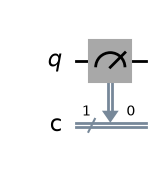

Imperfect preparation


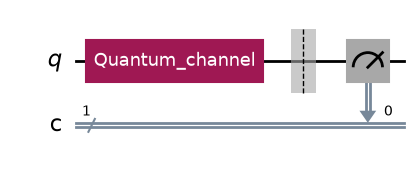

Perfect preparation: {'0': 1000}
Imperfect preparation: {'1': 111, '0': 889}


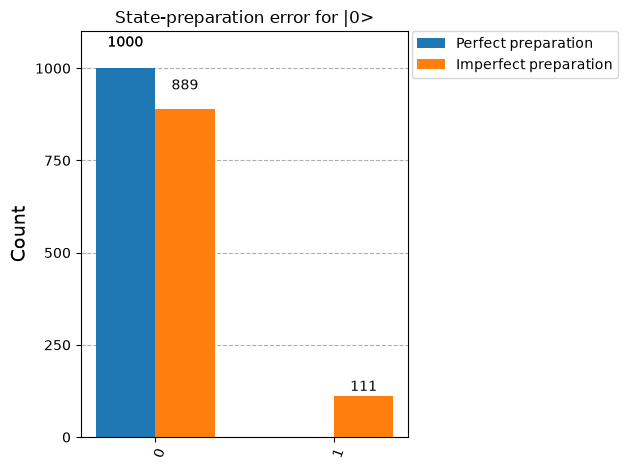

In [23]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import pauli_error
from qiskit.visualization import plot_histogram
from IPython.display import display
import matplotlib.pyplot as plt

simulator = AerSimulator()

# Preparation model:
# 90% probability of preparing |0>.
# 10% probability of preparing |1>.
error = pauli_error([
    ("I", 0.90),
    ("X", 0.10)
])

# Circuit with perfect preparation of |0>.
ideal = QuantumCircuit(1, 1)

ideal.measure(0, 0)

# Circuit with imperfect preparation.
faulty = QuantumCircuit(1, 1)

faulty.append(error.to_instruction(), [0])
faulty.barrier()

faulty.measure(0, 0)

# Display the circuits.
print("Perfect preparation")
display(ideal.draw("mpl"))
plt.close()

print("Imperfect preparation")
display(faulty.draw("mpl"))
plt.close()

# Prepare the circuits.
circuit_1 = transpile(ideal, simulator, optimization_level=0)
circuit_2 = transpile(faulty, simulator, optimization_level=0)

# Run each circuit 1000 times.
result_1 = simulator.run(circuit_1, shots=1000).result()
result_2 = simulator.run(circuit_2, shots=1000).result()

# Get the counts.
counts_1 = result_1.get_counts()
counts_2 = result_2.get_counts()

print("Perfect preparation:", counts_1)
print("Imperfect preparation:", counts_2)

# Display the histogram.
display(plot_histogram(
    [counts_1, counts_2],
    legend=["Perfect preparation", "Imperfect preparation"],
    title="State-preparation error for |0>"
))
plt.close()

For Readout Error

Without readout error


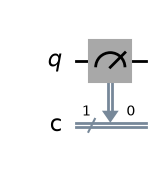

With readout error


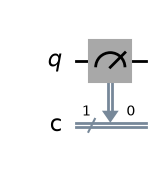

Without readout error: {'0': 1000}
With readout error: {'1': 113, '0': 887}


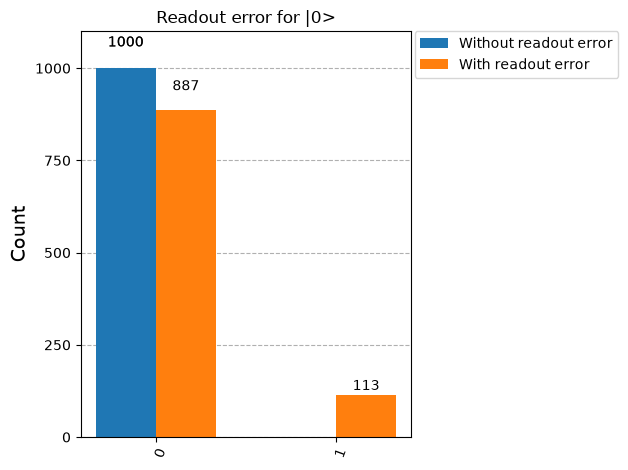

In [24]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError
from qiskit.visualization import plot_histogram
from IPython.display import display
import matplotlib.pyplot as plt

# Simulator without error.
simulator = AerSimulator()

# Probabilities of recording the measurement incorrectly.
readout_error = ReadoutError([
    [0.90, 0.10],   # True 0: record 0 with 90%, 1 with 10%.
    [0.20, 0.80]    # True 1: record 0 with 20%, 1 with 80%.
])

# Add readout error to qubit 0.
noise_model = NoiseModel()
noise_model.add_readout_error(readout_error, [0])

# Simulator with readout error.
error_simulator = AerSimulator(noise_model=noise_model)

# Circuit without readout error.
ideal = QuantumCircuit(1, 1)

ideal.measure(0, 0)

# Same circuit, run using the simulator with readout error.
faulty = QuantumCircuit(1, 1)

faulty.measure(0, 0)

# Display the circuits.
print("Without readout error")
display(ideal.draw("mpl"))
plt.close()

print("With readout error")
display(faulty.draw("mpl"))
plt.close()

# Prepare the circuits.
circuit_1 = transpile(ideal, simulator, optimization_level=0)
circuit_2 = transpile(
    faulty, error_simulator, optimization_level=0
)

# Run each circuit 1000 times.
result_1 = simulator.run(circuit_1, shots=1000).result()
result_2 = error_simulator.run(circuit_2, shots=1000).result()

# Get the counts.
counts_1 = result_1.get_counts()
counts_2 = result_2.get_counts()

print("Without readout error:", counts_1)
print("With readout error:", counts_2)

# Display the histogram.
display(plot_histogram(
    [counts_1, counts_2],
    legend=["Without readout error", "With readout error"],
    title="Readout error for |0>"
))
plt.close()

For Crosstalk error

Without crosstalk


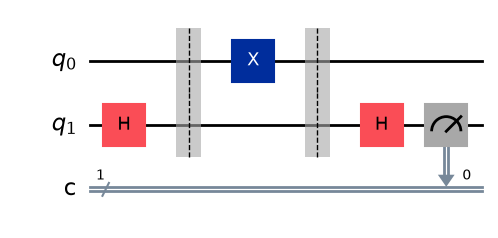

With crosstalk


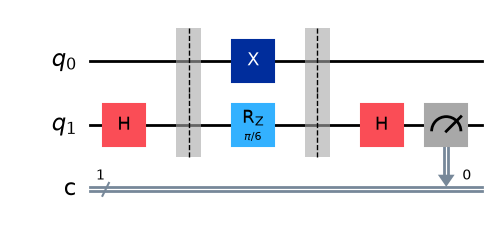

Without crosstalk: {'0': 1000}
With crosstalk: {'1': 74, '0': 926}


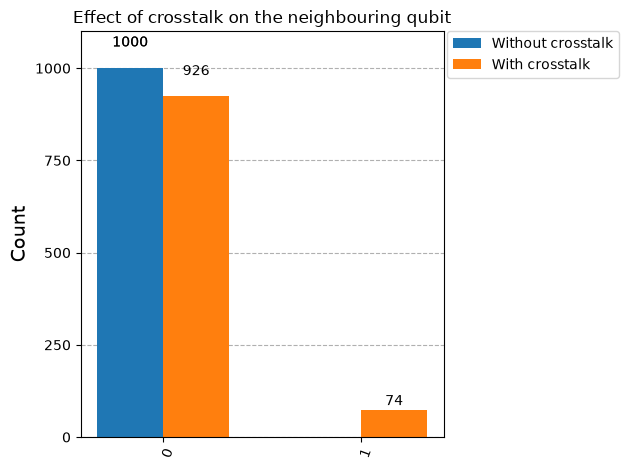

In [25]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np

# Use a simulator without the previous readout-error model.
simulator = AerSimulator()

# Circuit without crosstalk.
ideal = QuantumCircuit(2, 1)

ideal.h(1)           # Prepare neighbour in |+>
ideal.barrier()

ideal.x(0)           # Intended operation on qubit 0
ideal.barrier()

ideal.h(1)           # X-basis measurement of neighbour
ideal.measure(1, 0)

# Circuit with crosstalk.
faulty = QuantumCircuit(2, 1)

faulty.h(1)          # Prepare neighbour in |+>
faulty.barrier()

faulty.x(0)                  # Intended operation
faulty.rz(np.pi / 6, 1)       # Unwanted effect on neighbour
faulty.barrier()

faulty.h(1)          # X-basis measurement of neighbour
faulty.measure(1, 0)

# Display the circuits.
print("Without crosstalk")
display(ideal.draw("mpl"))
plt.close()

print("With crosstalk")
display(faulty.draw("mpl"))
plt.close()

# Prepare the circuits.
circuit_1 = transpile(ideal, simulator, optimization_level=0)
circuit_2 = transpile(faulty, simulator, optimization_level=0)

# Run each circuit 1000 times.
result_1 = simulator.run(circuit_1, shots=1000).result()
result_2 = simulator.run(circuit_2, shots=1000).result()

# Get the counts.
counts_1 = result_1.get_counts()
counts_2 = result_2.get_counts()

print("Without crosstalk:", counts_1)
print("With crosstalk:", counts_2)

# Display the histogram.
display(plot_histogram(
    [counts_1, counts_2],
    legend=["Without crosstalk", "With crosstalk"],
    title="Effect of crosstalk on the neighbouring qubit"
))
plt.close()
